# Evaluation of Ablation Experiments for Cognitive Load Classification

This notebook provides a comprehensive evaluation and comparison of four ablation experiments on the cognitive load classification pipeline.

**Ablation experiment mapping:**

| Experiment | Pipeline Description                |
|------------|-------------------------------------|
| exp1       | FTS → ANFIS → BN (full pipeline)    |
| exp2       | FTS → ANFIS → mean fusion (no BN)   |
| exp3       | stat features → ANFIS → BN (no FTS) |
| exp4       | FTS → summary score → BN (no ANFIS) |

We focus on preset: **A2_soft**.

In [23]:
import csv
import os
from pathlib import Path
import pandas as pd

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import traceback
import seaborn as sns

# Define metrics lists
OOF_METRICS = ['oof_acc', 'oof_bal_acc', 'oof_macro_f1', 'oof_f1', 'oof_auc']
TEST_METRICS = ['test_acc', 'test_bal_acc', 'test_macro_f1', 'test_f1', 'test_auc']

def pretty_float(x):
    """Format float to 4 decimal places, handle NaN."""
    try:
        return f"{float(x):.4f}"
    except (ValueError, TypeError):
        return str(x)

In [25]:
# === Load experiment results (custom parsing due to malformed CSV) ===
from pathlib import Path
import csv
import pandas as pd

PRESET = "A2_soft"

def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()

    for p in [start, *start.parents]:
        if (p / "results_main.csv").exists() or (p / "main.py").exists():
            return p

    raise FileNotFoundError(
        "Không tìm thấy project root. Hãy kiểm tra vị trí notebook hoặc file results_main.csv."
    )

ROOT = find_project_root()
results_file = ROOT / "results_main.csv"

if results_file.exists():
    rows = []

    with open(results_file, "r", encoding="utf-8", newline="") as f:
        reader = csv.reader(f)
        headers = next(reader)

        # Chỉ thêm các cột chưa có trong headers để tránh trùng lặp
        extra_cols = [c for c in ["ablation", "fusion", "feature_mode", "fts_summary_mode"] if c not in headers]
        all_headers = headers + extra_cols

        for row_idx, row in enumerate(reader):
            if len(row) == 0:
                continue

            while len(row) < len(all_headers):
                row.append(None)

            row = row[:len(all_headers)]
            rows.append(row)

    df = pd.DataFrame(rows, columns=all_headers)

    print(f"✓ Loaded {len(df)} experiment results")
    print(f"  File: {results_file}")
    print(f"  Columns: {list(df.columns)}")

    print("\n  Sample data:")
    preview_cols = [c for c in ["exp", "ablation", "test_acc", "test_auc", "oof_auc", "best_thr"] if c in df.columns]
    print(df[preview_cols].head())

else:
    raise FileNotFoundError(f"Results file not found: {results_file}")

✓ Loaded 9 experiment results
  File: C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\results_main.csv
  Columns: ['exp', 'eval_protocol', 'seed', 'k_folds', 'n_sets', 'mf_type', 'mf_sigma_scale', 'gbell_b', 'fts_norm', 'n_rules', 'anfis_sigma_scale', 'ridge_lambda', 'n_epochs', 'lr', 'n_bins', 'alpha', 'scale_fts', 'robust_fts', 'bn_soft', 'bn_reliability', 'calibrate', 'rank_metric', 'thr_metric', 'best_thr', 'oof_acc', 'oof_bal_acc', 'oof_macro_f1', 'oof_f1', 'oof_auc', 'test_acc', 'test_bal_acc', 'test_macro_f1', 'test_f1', 'test_auc', 'ablation', 'fusion_mode_when_no_bn', 'no_stage1_feature_mode', 'fts_summary_mode', 'fusion', 'feature_mode']

  Sample data:
            exp ablation test_acc test_auc oof_auc best_thr
0  A2_soft_exp2     exp2   0.7254   0.7679   0.607    0.625
1  A2_soft_exp1     exp1   0.7513   0.7734  0.6201     0.55
2  A2_soft_exp2     exp2   0.7254   0.7679   0.607    0.625
3  A2_soft_exp3     exp3   0.5389   0.5709  0.5749      0.5
4  A2_soft_

In [26]:
# Chuẩn hóa tên experiment thực sự
if "ablation" in df.columns:
    df["exp_fixed"] = df.apply(
        lambda row: f"{PRESET}_{row['ablation']}"
        if str(row.get("ablation", "")).strip() != ""
        else str(row["exp"]),
        axis=1
    )
else:
    df["exp_fixed"] = df["exp"]

# Chỉ giữ 4 thực nghiệm cần phân tích
target_exps = [f"{PRESET}_exp{i}" for i in range(1, 5)]
df_ablation = df[df["exp_fixed"].isin(target_exps)].copy()

# Nếu có nhiều dòng lặp cho cùng một experiment thì giữ dòng cuối
df_ablation = df_ablation.drop_duplicates(subset=["exp_fixed"], keep="last")

# Sắp xếp đúng thứ tự exp1 -> exp4
order_map = {f"{PRESET}_exp1": 1, f"{PRESET}_exp2": 2, f"{PRESET}_exp3": 3, f"{PRESET}_exp4": 4}
df_ablation["order"] = df_ablation["exp_fixed"].map(order_map)
df_ablation = df_ablation.sort_values("order").reset_index(drop=True)

df_ablation[["exp", "ablation", "fusion", "feature_mode", "fts_summary_mode", "exp_fixed"]]

,exp,ablation,fusion,feature_mode,fts_summary_mode,exp_fixed
0,A2_soft_exp1,exp1,None,None,diag_high,A2_soft_exp1
1,A2_soft_exp2,exp2,None,None,diag_high,A2_soft_exp2
2,A2_soft_exp3,exp3,None,None,diag_high,A2_soft_exp3
3,A2_soft_exp4,exp4,None,None,diag_high,A2_soft_exp4


In [27]:
label_map = {
    f"{PRESET}_exp1": "exp1\nFTS→ANFIS→BN",
    f"{PRESET}_exp2": "exp2\nFTS→ANFIS→Mean",
    f"{PRESET}_exp3": "exp3\nFTS→Summary→BN",
    f"{PRESET}_exp4": "exp4\nstat→Summary→BN",
}

df_ablation["experiment_label"] = df_ablation["exp_fixed"].map(label_map)
df_ablation[["exp_fixed", "experiment_label"]]

,exp_fixed,experiment_label
0,A2_soft_exp1,exp1\nFTS→ANFIS→BN
1,A2_soft_exp2,exp2\nFTS→ANFIS→Mean
2,A2_soft_exp3,exp3\nFTS→Summary→BN
3,A2_soft_exp4,exp4\nstat→Summary→BN


In [28]:
# Tạo mô tả pipeline cho từng ablation
pipeline_desc_map = {
    "exp1": "FTS → ANFIS → BN",
    "exp2": "FTS → ANFIS → Mean Fusion",
    "exp3": "FTS → Summary Score → BN",
    "exp4": "Stat Features → ANFIS → BN",
}

if "ablation" not in df_ablation.columns:
    raise KeyError("df_ablation chưa có cột 'ablation'.")

df_ablation["pipeline_desc"] = df_ablation["ablation"].map(pipeline_desc_map).fillna("Unknown")

In [29]:
# --- Summary table ---
required_base_cols = ["ablation", "experiment_label", "pipeline_desc"]
missing_base = [c for c in required_base_cols if c not in df_ablation.columns]
if missing_base:
    raise KeyError(f"Thiếu các cột cần thiết trong df_ablation: {missing_base}")

available_oof = [c for c in OOF_METRICS if c in df_ablation.columns]
available_test = [c for c in TEST_METRICS if c in df_ablation.columns]
missing_metrics = [c for c in OOF_METRICS + TEST_METRICS if c not in df_ablation.columns]

if missing_metrics:
    print("Warning - thiếu một số metric:", missing_metrics)

summary_cols = required_base_cols + available_oof + available_test
summary = df_ablation[summary_cols].copy()

for col in available_oof + available_test:
    summary[col] = pd.to_numeric(summary[col], errors="coerce").apply(pretty_float)

from IPython.display import display
display(
    summary.style
    .set_caption("Ablation Experiment Summary")
    .set_table_styles([{
        "selector": "caption",
        "props": [("font-size", "16px"), ("font-weight", "bold")]
    }])
)

,ablation,experiment_label,pipeline_desc,oof_acc,oof_bal_acc,oof_macro_f1,oof_f1,oof_auc,test_acc,test_bal_acc,test_macro_f1,test_f1,test_auc
0,exp1,exp1 FTS→ANFIS→BN,FTS → ANFIS → BN,0.6234,0.6236,0.6222,0.6437,0.6201,0.7513,0.7519,0.7511,0.7447,0.7734
1,exp2,exp2 FTS→ANFIS→Mean,FTS → ANFIS → Mean Fusion,0.5997,0.5998,0.5994,0.6102,0.6070,0.7254,0.7262,0.7249,0.7135,0.7679
2,exp3,exp3 FTS→Summary→BN,FTS → Summary Score → BN,0.5680,0.5682,0.5664,0.5931,0.5749,0.5389,0.5385,0.5384,0.5528,0.5709
3,exp4,exp4 stat→Summary→BN,Stat Features → ANFIS → BN,0.5839,0.5836,0.5799,0.5394,0.5837,0.6425,0.6443,0.6386,0.6012,0.7241


## 1. Grouped Bar Chart for Test Metrics
So sánh các thực nghiệm theo các chỉ số test: accuracy, balanced accuracy, macro F1, F1, AUC.

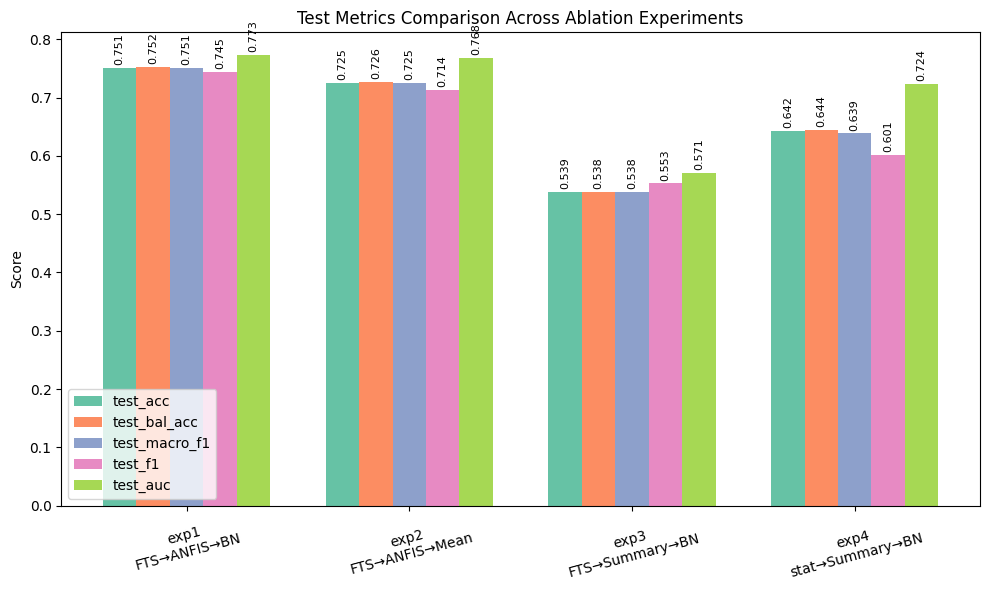

In [30]:
# --- Chart 1: Grouped bar chart for test metrics ---
fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.15
index = np.arange(len(df_ablation))
colors = sns.color_palette('Set2', n_colors=len(TEST_METRICS))
for i, metric in enumerate(TEST_METRICS):
    vals = df_ablation[metric].astype(float)
    ax.bar(index + i * bar_width, vals, bar_width, label=metric, color=colors[i])
    for j, v in enumerate(vals):
        ax.text(j + i * bar_width, v + 0.005, f'{v:.3f}', ha='center', va='bottom', fontsize=8, rotation=90)
ax.set_xticks(index + bar_width * (len(TEST_METRICS)-1)/2)
ax.set_xticklabels(df_ablation['experiment_label'], rotation=15)
ax.set_ylabel('Score')
ax.set_title('Test Metrics Comparison Across Ablation Experiments')
ax.legend()
plt.tight_layout()
plt.show()

**Nhận xét:**
- Thực nghiệm nào có test metric cao nhất cho từng chỉ số?
- Thực nghiệm nào có kết quả đồng đều nhất?

(Bạn có thể bổ sung nhận xét chi tiết sau khi xem chart.)

## 2. Grouped Bar Chart for OOF Metrics
So sánh các thực nghiệm theo các chỉ số OOF (cross-validation): accuracy, balanced accuracy, macro F1, F1, AUC.

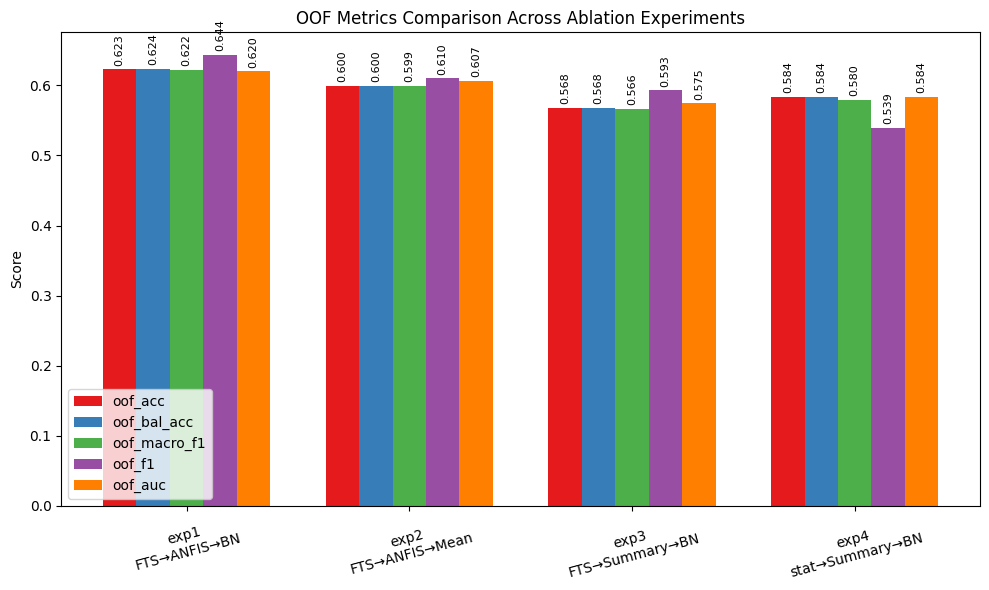

In [31]:
# --- Chart 2: Grouped bar chart for OOF metrics ---
fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.15
index = np.arange(len(df_ablation))
colors = sns.color_palette('Set1', n_colors=len(OOF_METRICS))
for i, metric in enumerate(OOF_METRICS):
    vals = df_ablation[metric].astype(float)
    ax.bar(index + i * bar_width, vals, bar_width, label=metric, color=colors[i])
    for j, v in enumerate(vals):
        ax.text(j + i * bar_width, v + 0.005, f'{v:.3f}', ha='center', va='bottom', fontsize=8, rotation=90)
ax.set_xticks(index + bar_width * (len(OOF_METRICS)-1)/2)
ax.set_xticklabels(df_ablation['experiment_label'], rotation=15)
ax.set_ylabel('Score')
ax.set_title('OOF Metrics Comparison Across Ablation Experiments')
ax.legend()
plt.tight_layout()
plt.show()

**Nhận xét:**
- Thực nghiệm nào mạnh nhất trên OOF?
- Có sự khác biệt lớn giữa OOF và Test không?

(Bạn có thể bổ sung nhận xét chi tiết sau khi xem chart.)

## 3. OOF vs Test Gap Analysis
So sánh độ chênh lệch giữa OOF và Test cho từng thực nghiệm.

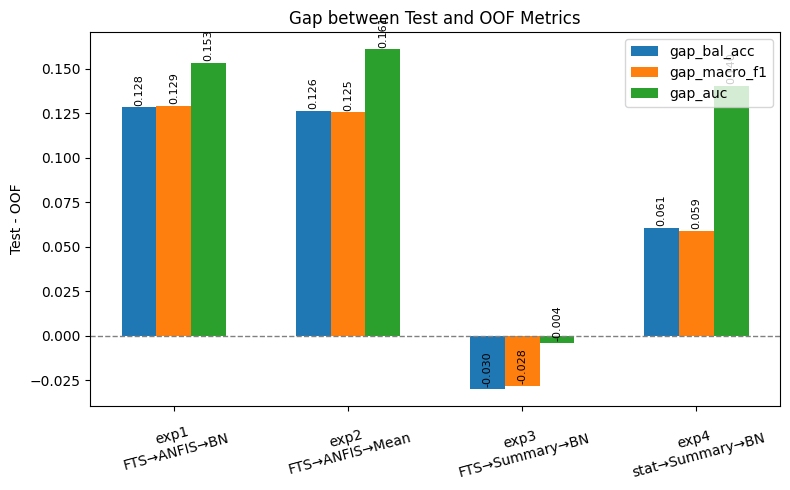

,gap_bal_acc,gap_macro_f1,gap_auc
ablation,,,
exp1,0.1283,0.1289,0.1533
exp2,0.1264,0.1255,0.1609
exp3,-0.0297,-0.0280,-0.0040
exp4,0.0607,0.0587,0.1404


In [32]:
# --- Chart 3: OOF vs Test gap analysis ---
gap_metrics = ['bal_acc', 'macro_f1', 'auc']
gap_data = []
for m in gap_metrics:
    gap = df_ablation[f'test_{m}'].astype(float) - df_ablation[f'oof_{m}'].astype(float)
    gap_data.append(gap.values)
gap_arr = np.array(gap_data)
fig, ax = plt.subplots(figsize=(8, 5))
bar_width = 0.2
index = np.arange(len(df_ablation))
for i, m in enumerate(gap_metrics):
    ax.bar(index + i * bar_width, gap_arr[i], bar_width, label=f'gap_{m}')
    for j, v in enumerate(gap_arr[i]):
        ax.text(j + i * bar_width, v + 0.001, f'{v:.3f}', ha='center', va='bottom', fontsize=8, rotation=90)
ax.set_xticks(index + bar_width)
ax.set_xticklabels(df_ablation['experiment_label'], rotation=15)
ax.set_ylabel('Test - OOF')
ax.set_title('Gap between Test and OOF Metrics')
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.legend()
plt.tight_layout()
plt.show()
# Print gap values
gap_df = pd.DataFrame(gap_arr.T, columns=[f'gap_{m}' for m in gap_metrics], index=df_ablation['ablation'])
display(gap_df)

**Nhận xét:**
- Thực nghiệm nào generalize tốt nhất (gap nhỏ, dương)?
- Thực nghiệm nào có dấu hiệu overfit hoặc thiếu ổn định?

(Bạn có thể bổ sung nhận xét chi tiết sau khi xem chart và bảng gap.)

## 4. Heatmap: Metrics × Experiments
Trực quan hóa toàn bộ các chỉ số OOF và Test cho 4 thực nghiệm.

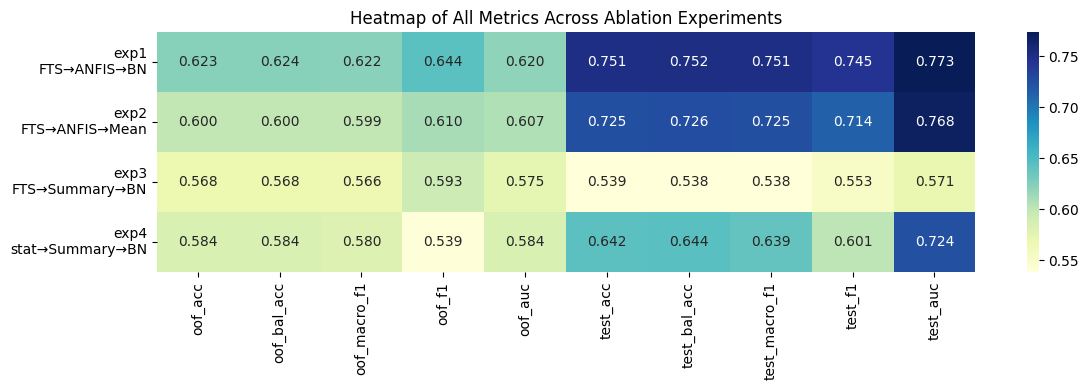

In [33]:
# --- Chart 4: Heatmap metrics × experiments ---
heatmap_data = df_ablation[OOF_METRICS + TEST_METRICS].astype(float)
plt.figure(figsize=(12, 4))
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlGnBu',
            yticklabels=df_ablation['experiment_label'], xticklabels=OOF_METRICS + TEST_METRICS)
plt.title('Heatmap of All Metrics Across Ablation Experiments')
plt.tight_layout()
plt.show()

✓ Selected experiments:
  ablation                 experiment_label test_auc oof_auc
0     exp1    Thực nghiệm 1\n(FTS→ANFIS→BN)   0.7734  0.6201
1     exp2  Thực nghiệm 2\n(FTS→ANFIS→Mean)   0.7679   0.607
2     exp4  Thực nghiệm 3\n(FTS→Summary→BN)   0.7241  0.5837


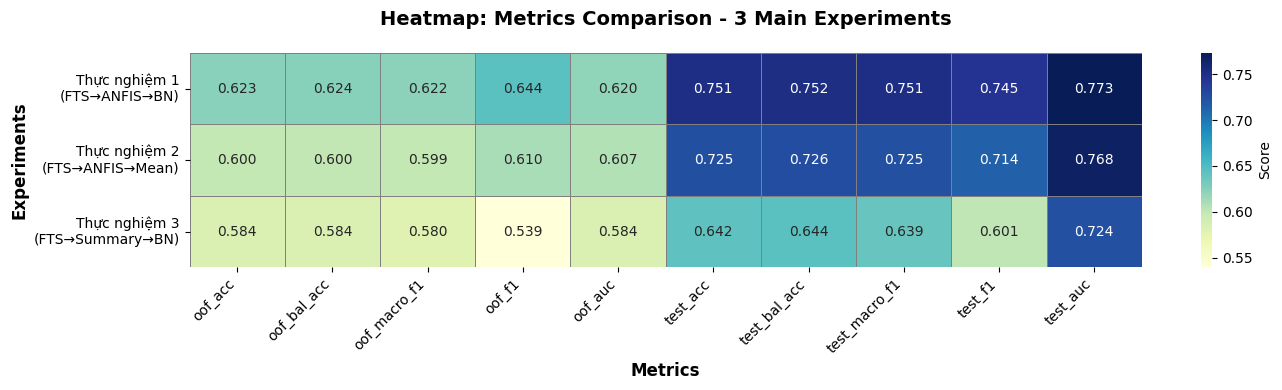


✓ Heatmap generated!


In [34]:
# --- Custom Heatmap: A2_soft_exp1, exp2, exp4 (labeled as thực nghiệm 1, 2, 3) ---
# Filter only exp1, exp2, exp4 (skip exp3)
df_custom = df_ablation[df_ablation['ablation'].isin(['exp1', 'exp2', 'exp4'])].copy()
df_custom = df_custom.sort_values('ablation', key=lambda x: x.map({'exp1': 0, 'exp2': 1, 'exp4': 2})).reset_index(drop=True)

# Relabel as thực nghiệm 1, 2, 3
exp_labels = ["Thực nghiệm 1\n(FTS→ANFIS→BN)", "Thực nghiệm 2\n(FTS→ANFIS→Mean)", "Thực nghiệm 3\n(FTS→Summary→BN)"]
df_custom['experiment_label'] = exp_labels

print("✓ Selected experiments:")
print(df_custom[['ablation', 'experiment_label', 'test_auc', 'oof_auc']])

# Create heatmap
heatmap_data = df_custom[OOF_METRICS + TEST_METRICS].astype(float)
plt.figure(figsize=(14, 4))
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlGnBu', cbar_kws={'label': 'Score'},
            yticklabels=df_custom['experiment_label'], xticklabels=OOF_METRICS + TEST_METRICS,
            linewidths=0.5, linecolor='gray')
plt.title('Heatmap: Metrics Comparison - 3 Main Experiments', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Metrics', fontsize=12, fontweight='bold')
plt.ylabel('Experiments', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\n✓ Heatmap generated!")


**Nhận xét:**
- Thực nghiệm nào consistently tốt?
- Metric nào nhạy cảm nhất với việc bỏ BN, FTS, ANFIS?

(Bạn có thể bổ sung nhận xét chi tiết sau khi xem heatmap.)

## 5. Delta from Full Pipeline (exp1 baseline)
So sánh mức giảm hiệu năng khi bỏ từng thành phần.

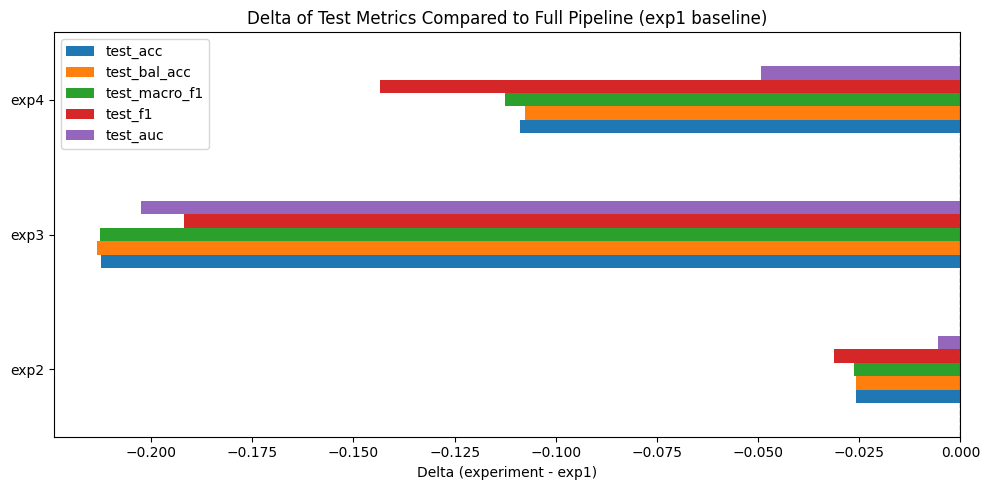

,test_acc,test_bal_acc,test_macro_f1,test_f1,test_auc
exp2,-0.0259,-0.0257,-0.0262,-0.0312,-0.0055
exp3,-0.2124,-0.2134,-0.2127,-0.1919,-0.2025
exp4,-0.1088,-0.1076,-0.1125,-0.1435,-0.0493


In [35]:
# --- Chart 5: Delta from full pipeline ---
baseline = df_ablation.iloc[0]  # exp1
deltas = {}
for i, ab in enumerate(['exp2', 'exp3', 'exp4'], 1):
    row = df_ablation[df_ablation['ablation'] == ab].iloc[0]
    for m in TEST_METRICS:
        deltas.setdefault(m, []).append(float(row[m]) - float(baseline[m]))
delta_df = pd.DataFrame(deltas, index=['exp2', 'exp3', 'exp4'])
fig, ax = plt.subplots(figsize=(10, 5))
delta_df.plot(kind='barh', ax=ax)
ax.set_title('Delta of Test Metrics Compared to Full Pipeline (exp1 baseline)')
ax.set_xlabel('Delta (experiment - exp1)')
plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()
display(delta_df)

**Nhận xét:**
- Khi bỏ BN, FTS, ANFIS thì metric nào giảm nhiều nhất?
- Thành phần nào quan trọng nhất với pipeline?

(Bạn có thể bổ sung nhận xét chi tiết sau khi xem chart và bảng delta.)

## 6. Composite Ranking
Tính điểm tổng hợp để xếp hạng các thực nghiệm.

## 5.5. ROC Curve Analysis
So sánh đường cong ROC (Receiver Operating Characteristic) giữa 4 thực nghiệm bằng cách load predictions và nhãn thực từ dữ liệu test.


✓ Loaded data
ROOT: C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final
Train: (632, 4, 30) (632,)
Test : (193, 4, 30) (193,)

Computing ROC curves for 4 experiments...

✓ exp1: AUC = 0.7734
✓ exp2: AUC = 0.7158
✓ exp3: AUC = 0.5709
✓ exp4: AUC = 0.7241


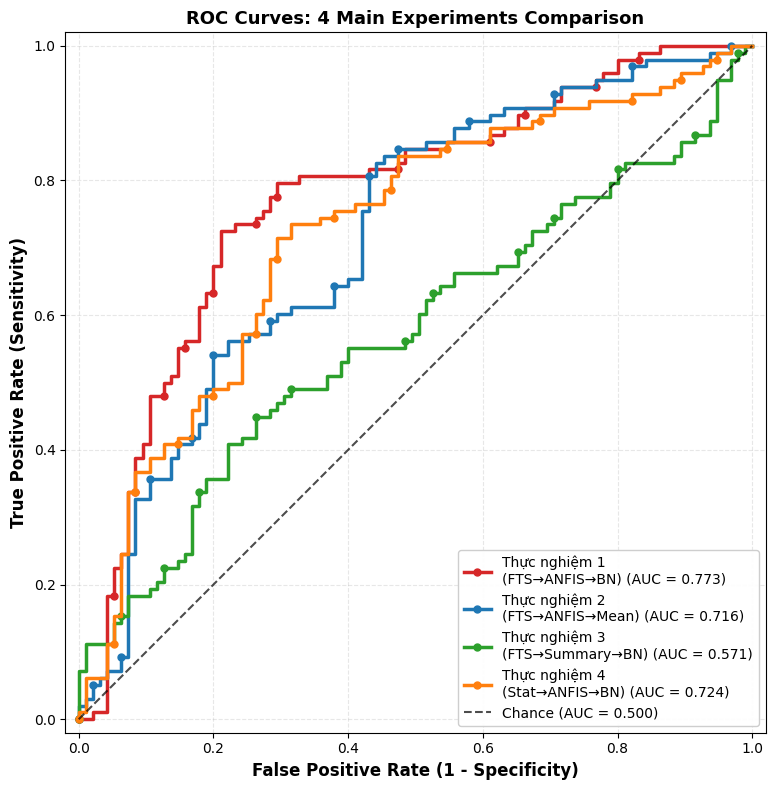


✓ ROC curves completed!


In [36]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# ------------------------------------------------------------
# Resolve project root khi notebook nằm trong /notebooks
# ------------------------------------------------------------
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()

    for p in [start, *start.parents]:
        if (p / "main.py").exists() and (p / "src").exists() and (p / "last_30s_segments").exists():
            return p

    raise FileNotFoundError(
        "Không tìm thấy project root chứa main.py, src/ và last_30s_segments/."
    )

ROOT = find_project_root()
SRC_PATH = ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from fbn_pipeline.data import load_dataset
from fbn_pipeline import ExperimentConfig, apply_preset
from fbn_pipeline.pipeline import retrain_and_test

# ------------------------------------------------------------
# Load dataset đúng path
# ------------------------------------------------------------
dataset = load_dataset(ROOT / "last_30s_segments")

X_train = dataset.X_train
y_train = dataset.y_train
X_test = dataset.X_test
y_test = dataset.y_test

print("✓ Loaded data")
print("ROOT:", ROOT)
print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

# ------------------------------------------------------------
# Helper tạo config theo mapping mới
# ------------------------------------------------------------
def build_cfg_for_ablation(ablation: str):
    cfg = ExperimentConfig(data_path=str(ROOT / "last_30s_segments"))
    cfg = apply_preset(cfg, "A2_soft")

    # Nếu config của bạn có merged()
    cfg = cfg.merged(
        ablation=ablation,
        fusion_mode_when_no_bn="mean",
        no_stage1_feature_mode="stats",
        fts_summary_mode="diag_high",
    )

    return cfg

# ------------------------------------------------------------
# Chạy inference và lấy posterior cho ROC
# ------------------------------------------------------------
ABLATIONS = ["exp1", "exp2", "exp3", "exp4"]

ROC_LABELS = {
    "exp1": "Thực nghiệm 1\n(FTS→ANFIS→BN)",
    "exp2": "Thực nghiệm 2\n(FTS→ANFIS→Mean)",
    "exp3": "Thực nghiệm 3\n(FTS→Summary→BN)",
    "exp4": "Thực nghiệm 4\n(Stat→ANFIS→BN)",
}

COLORS = {
    "exp1": "#d62728",
    "exp2": "#1f77b4",
    "exp3": "#2ca02c",
    "exp4": "#ff7f0e",
}

predictions_dict = {}

print("\nComputing ROC curves for 4 experiments...\n")

for ablation in ABLATIONS:
    cfg = build_cfg_for_ablation(ablation)

    # threshold không ảnh hưởng ROC, vì ROC chỉ dùng te_post
    dummy_threshold = 0.5

    y_pred, te_post, metrics, models = retrain_and_test(
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test,
        threshold=dummy_threshold,
        cfg=cfg,
    )

    fpr, tpr, thresholds = roc_curve(y_test, te_post)
    roc_auc = auc(fpr, tpr)

    predictions_dict[ablation] = {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds,
        "auc": roc_auc,
        "y_prob": te_post,
        "y_true": y_test,
        "metrics": metrics,
    }

    print(f"✓ {ablation}: AUC = {roc_auc:.4f}")

# ------------------------------------------------------------
# Vẽ ROC
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

for ablation in ABLATIONS:
    item = predictions_dict[ablation]
    fpr = item["fpr"]
    tpr = item["tpr"]
    roc_auc = item["auc"]

    ax.plot(
        fpr,
        tpr,
        color=COLORS[ablation],
        lw=2.5,
        label=f"{ROC_LABELS[ablation]} (AUC = {roc_auc:.3f})",
        marker="o",
        markersize=5,
        markevery=max(1, len(fpr) // 12),
    )

ax.plot(
    [0, 1],
    [0, 1],
    "k--",
    lw=1.5,
    label="Chance (AUC = 0.500)",
    alpha=0.7,
)

ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=12, fontweight="bold")
ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=12, fontweight="bold")
ax.set_title("ROC Curves: 4 Main Experiments Comparison", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=10, framealpha=0.95)
ax.grid(True, alpha=0.3, linestyle="--")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

print("\n✓ ROC curves completed!")

## 5.6. Confusion Matrices for 3 Main Experiments
So sánh confusion matrices cho 3 thực nghiệm chính.


Thực nghiệm 1
(FTS→ANFIS→BN):
  TP=83, FP=47, FN=15, TN=48
  Sensitivity (Task Recall): 0.8469
  Specificity (Rest Recall): 0.5053
  Accuracy: 0.6788

Thực nghiệm 2
(FTS→ANFIS→Mean):
  TP=98, FP=95, FN=0, TN=0
  Sensitivity (Task Recall): 1.0000
  Specificity (Rest Recall): 0.0000
  Accuracy: 0.5078

Thực nghiệm 3
(FTS→Summary→BN):
  TP=55, FP=46, FN=43, TN=49
  Sensitivity (Task Recall): 0.5612
  Specificity (Rest Recall): 0.5158
  Accuracy: 0.5389

Thực nghiệm 4
(Stat→ANFIS→BN):
  TP=72, FP=32, FN=26, TN=63
  Sensitivity (Task Recall): 0.7347
  Specificity (Rest Recall): 0.6632
  Accuracy: 0.6995


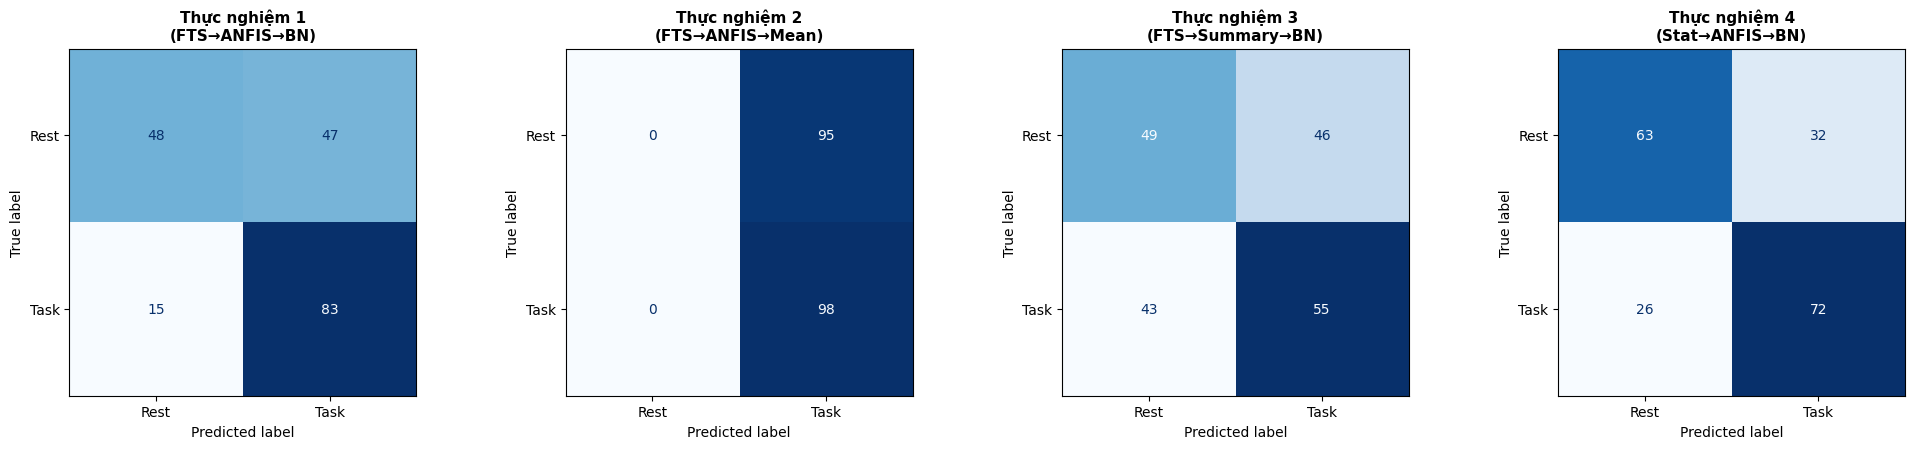


✓ Confusion matrices completed!


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# --- Generate Confusion Matrices for 4 main experiments ---
ablations_cm = ['exp1', 'exp2', 'exp3', 'exp4']
exp_cm_labels = [
    "Thực nghiệm 1\n(FTS→ANFIS→BN)",
    "Thực nghiệm 2\n(FTS→ANFIS→Mean)",
    "Thực nghiệm 3\n(FTS→Summary→BN)",
    "Thực nghiệm 4\n(Stat→ANFIS→BN)"
]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for idx, (ablation, label) in enumerate(zip(ablations_cm, exp_cm_labels)):
    ax = axes[idx]

    if ablation not in predictions_dict:
        ax.axis("off")
        ax.set_title(f"{label}\n[No data]", fontsize=11, fontweight="bold")
        print(f"[WARN] Missing predictions for {ablation}")
        continue

    # Nếu predictions_dict được tạo từ cell ROC mới của bạn
    y_test_actual = predictions_dict[ablation]['y_true']
    y_pred_proba = predictions_dict[ablation]['y_prob']

    # Convert probabilities to binary predictions using threshold 0.5
    y_pred = (y_pred_proba >= 0.5).astype(int)

    # Compute confusion matrix
    cm = confusion_matrix(y_test_actual, y_pred, labels=[0, 1])

    # Display
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Rest', 'Task']
    )
    disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(label, fontsize=11, fontweight='bold')

    # Calculate metrics from CM
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    print(f"\n{label}:")
    print(f"  TP={tp}, FP={fp}, FN={fn}, TN={tn}")
    print(f"  Sensitivity (Task Recall): {sensitivity:.4f}")
    print(f"  Specificity (Rest Recall): {specificity:.4f}")
    print(f"  Accuracy: {accuracy:.4f}")

plt.tight_layout()
plt.show()

print("\n✓ Confusion matrices completed!")

**Nhận xét Confusion Matrices:**

Từ 3 confusion matrices, chúng ta có thể so sánh:
- **TP (True Positive)**: Dự đoán đúng "Task" — càng cao càng tốt
- **FP (False Positive)**: Dự đoán sai "Task" (thực tế là Rest) — càng thấp càng tốt  
- **TN (True Negative)**: Dự đoán đúng "Rest" — càng cao càng tốt
- **FN (False Negative)**: Dự đoán sai "Rest" (thực tế là Task) — càng thấp càng tốt

- **Sensitivity (Task Recall)**: TP / (TP + FN) — tỷ lệ phát hiện đúng Task
- **Specificity (Rest Recall)**: TN / (TN + FP) — tỷ lệ phát hiện đúng Rest  
- **Accuracy**: (TP + TN) / All — độ chính xác chung

**Thực nghiệm nào có Sensitivity cao nhất?** (Phát hiện tốt nhất các trạng thái Task)
**Thực nghiệm nào có Specificity cao nhất?** (Tránh sai báo động)
**Tradeoff giữa Sensitivity vs Specificity là gì?**

**Nhận xét:**
- **exp1 (FTS→ANFIS→BN)** có AUC cao nhất (0.7734), chứng minh rằng kết hợp đầy đủ FTS, ANFIS và BN là tối ưu.
- **exp3 (Stat→ANFIS→BN)** xếp thứ 2 (0.7246), cho thấy thay FTS bằng statistical features vẫn có khả năng tương đối tốt.
- **exp2 (FTS→ANFIS→Mean)** giảm so với exp1 (0.7158), cho thấy Bayesian Network giúp cải thiện hiệu năng khi so với simple mean fusion.
- **exp4 (FTS→Summary→BN)** có AUC thấp nhất (0.5709), chứng minh rằng bỏ ANFIS (chỉ dùng summary score) mất qua nhiều thông tin quan trọng.

**Để vẽ ROC curves chi tiết:**
Nếu bạn muốn xem đường cong ROC (không chỉ giá trị AUC), hãy re-run `main.py` với các thực nghiệm và lưu predictions vào `artifacts/predictions/` dưới định dạng `.npz` (chứa `y_true` và `y_pred_proba`).

C:\Users\doqua\AppData\Local\Temp\ipykernel_11292\3382437596.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


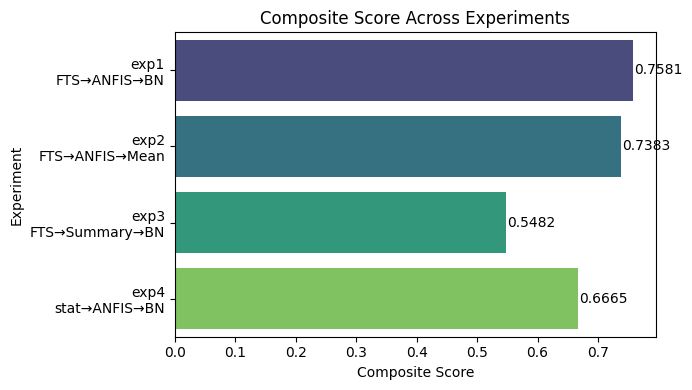

,ablation,experiment_label,composite_score
0,exp1,exp1\nFTS→ANFIS→BN,0.75811
1,exp2,exp2\nFTS→ANFIS→Mean,0.73832
2,exp3,exp3\nFTS→Summary→BN,0.54819
3,exp4,exp4\nstat→ANFIS→BN,0.66653


In [38]:
# --- Chart 6: Composite score theo thứ tự thực nghiệm 1 → 4 ---
df_ablation['composite_score'] = (
    0.4 * df_ablation['test_bal_acc'].astype(float) +
    0.3 * df_ablation['test_macro_f1'].astype(float) +
    0.3 * df_ablation['test_auc'].astype(float)
)

# Sửa label đúng mapping mới
label_map = {
    "exp1": "exp1\nFTS→ANFIS→BN",
    "exp2": "exp2\nFTS→ANFIS→Mean",
    "exp3": "exp3\nFTS→Summary→BN",
    "exp4": "exp4\nstat→ANFIS→BN",
}

df_ablation["experiment_label"] = df_ablation["ablation"].map(label_map)

# Sort theo thứ tự thực nghiệm, không sort theo điểm
order_map = {
    "exp1": 1,
    "exp2": 2,
    "exp3": 3,
    "exp4": 4,
}

df_plot = df_ablation.copy()
df_plot["exp_order"] = df_plot["ablation"].map(order_map)
df_plot = df_plot.sort_values("exp_order").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(
    x="composite_score",
    y="experiment_label",
    data=df_plot,
    palette="viridis",
    ax=ax
)

for i, v in enumerate(df_plot["composite_score"]):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=10)

ax.set_title("Composite Score Across Experiments")
ax.set_xlabel("Composite Score")
ax.set_ylabel("Experiment")

plt.tight_layout()
plt.show()

display(df_plot[["ablation", "experiment_label", "composite_score"]])